# 04: Walk-Forward Engine and the Breakdown Kill-Switch

v1 selected pairs once and traded them for years. This notebook covers
the two v2 changes that attack that directly.

**Walk-forward re-formation.** Every six months I re-run the entire
cointegration selection on the trailing two years (the formation window)
across a ~100-ticker universe, then trade the surviving pairs for the
next six months only. No pair is ever traded on evidence more than six
months stale. Each cycle's formation strictly precedes its trading
window, so the procedure is look-ahead-free by construction.

**The kill-switch.** Cointegration established on a formation window is
a hypothesis, not a property. I monitor every live pair two ways: a slow
rolling ADF re-test (blocks new entries when the spread stops looking
stationary) and a fast Bayesian online changepoint detector (BOCPD,
Adams and MacKay 2007) on standardized spread changes, which force-exits
when the posterior says the data-generating process changed recently. I
require the alarm to persist five consecutive days, because I measured
on synthetic data that a one-day outlier sustains the alarm about three
days while a genuine process change sustains it nine to ten.

In [1]:
# Setup: make src importable and load shared inputs
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks"
                       else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from src import (universe, cointegration, kalman_hedge, regime_detector,
                 signal_generator, backtest, report, config)

prices = universe.download_universe()
splits = universe.load_splits()
stocks = prices[universe.stock_columns(prices)]
vix = prices[config.VIX_TICKER]
train = universe.get_split(stocks, "train")
print("data:", prices.shape, "| splits:", splits)

data: (1257, 41) | splits: {'train': ['2021-06-11', '2024-06-10'], 'validation': ['2024-06-11', '2025-06-11'], 'test': ['2025-06-12', '2026-06-11']}


In [2]:
from src import walkforward, break_detector, ou_model

prices_v2 = universe.download_universe_v2()
splits_v2 = universe.load_splits_v2()
params_v2 = json.loads(config.TUNED_V2_JSON.read_text())
print("v2 universe:", prices_v2.shape)
print("frozen v2 params:", {k: params_v2[k] for k in ("delta","center","n_configs")})

cycles = walkforward.make_cycles(prices_v2.index, *splits_v2["development"])
print(f"{len(cycles)} development cycles; example:")
for cyc in cycles[:3]:
    print(f"  form {cyc['f_start'].date()} -> {cyc['f_end'].date()}, "
          f"trade {cyc['t_start'].date()} -> {cyc['t_end'].date()}")

v2 universe: (2515, 98)
frozen v2 params: {'delta': 0.0001, 'center': 'rolling', 'n_configs': 9}
14 development cycles; example:
  form 2016-06-13 -> 2018-06-12, trade 2018-06-13 -> 2018-12-11
  form 2016-12-09 -> 2018-12-11, trade 2018-12-12 -> 2019-06-13
  form 2017-06-13 -> 2019-06-13, trade 2019-06-14 -> 2019-12-11


## Pair turnover: the reason walk-forward matters

If the same pairs survived every re-formation, walk-forward would be
pointless. The turnover chart shows the opposite: the cointegrated set
changes substantially every six months, which means a static selection
(v1) spends most of its life trading relationships that current data no
longer supports.

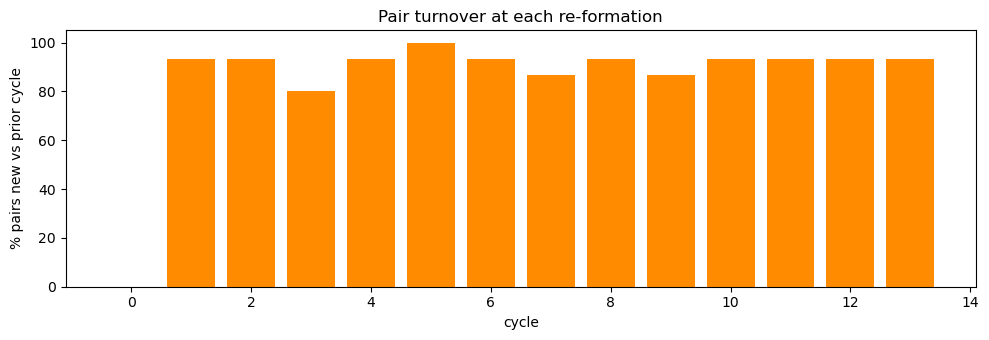

median turnover: 93%


In [3]:
pairs_dev = pd.read_csv(config.RESULTS_DIR / "wf_pairs_dev.csv")
per_cycle = pairs_dev.groupby("cycle")["pair"].apply(set)
turnover = [np.nan] + [1 - len(per_cycle.iloc[i] & per_cycle.iloc[i-1])
                       / max(len(per_cycle.iloc[i]), 1)
                       for i in range(1, len(per_cycle))]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(per_cycle.index, [t*100 if t==t else 0 for t in turnover], color="darkorange")
ax.set_ylabel("% pairs new vs prior cycle"); ax.set_xlabel("cycle")
ax.set_title("Pair turnover at each re-formation")
plt.tight_layout(); plt.show()
print(f"median turnover: {np.nanmedian(turnover):.0%}")

## The OU s-score

For the score I fit the spread's AR(1)/Ornstein-Uhlenbeck dynamics on
the formation window and freeze the equilibrium m and the stationary
sigma_eq for the trading window. Unlike a short rolling std, sigma_eq
cannot be inflated by the dislocation being traded, so "s = 2" means the
same thing on every day of the trading window.

pair PEP/TGT: OU m=-6.99, sigma_eq=6.47, half-life=13.5d


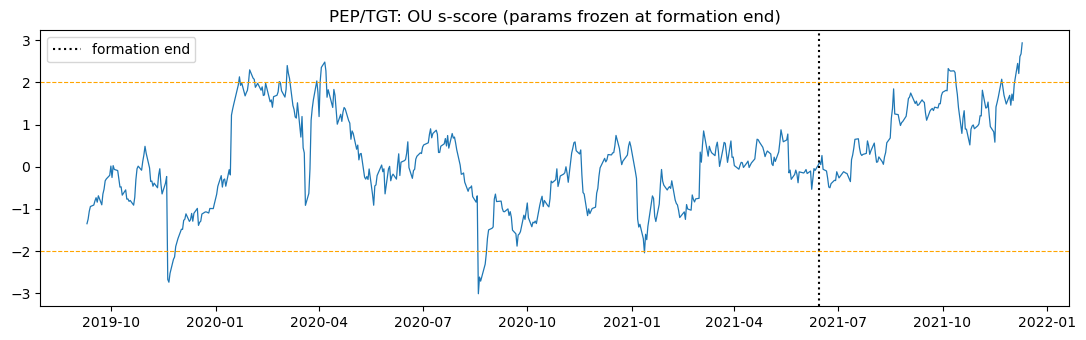

In [4]:
ci = walkforward.prepare_cycle(prices_v2, cycles[6], params_v2["delta"])
name, d = next(iter(ci["per_pair"].items()))
spread = d["kf"]["spread"]
ou = d["ou"]
print(f"pair {name}: OU m={ou['m']:.2f}, sigma_eq={ou['sigma_eq']:.2f}, "
      f"half-life={ou['half_life']:.1f}d")
s = ou_model.s_score(spread, ou)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(s.iloc[60:], lw=0.9)
ax.axvline(ci["cycle"]["f_end"], color="k", ls=":", label="formation end")
for lvl in (2, -2): ax.axhline(lvl, color="orange", lw=0.8, ls="--")
ax.legend(); ax.set_title(f"{name}: OU s-score (params frozen at formation end)")
plt.tight_layout(); plt.show()

## What the kill-switch buys

Same development run, same configuration, with and without the
kill-switch. The exit reason "break" marks force-exits where BOCPD
detected a process change under the persistence rule. The point of this
comparison is tail protection: the kill-switch should cut the worst
losses even if it costs some winners.

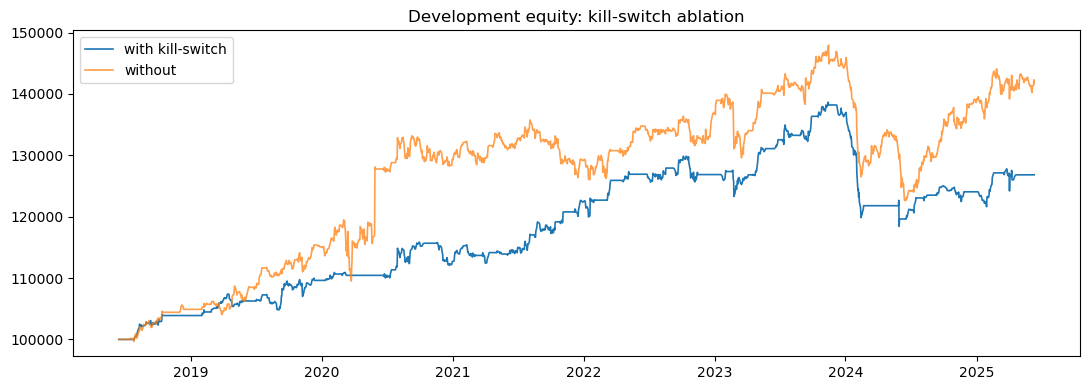

exit reasons (with kill-switch):
exit_reason
signal           108
break             14
end_of_period      6
stop               2
timeout            1

worst 5 trades with KS:    [-11042.684683255393, -4820.149997848869, -2856.1999403319455, -2282.7502681061274, -2251.6107013583473]
worst 5 trades without KS: [-11687.758915896313, -7557.876859705985, -6695.669962622022, -5586.820683545093, -5413.542126013654]


In [5]:
eq = pd.read_csv(config.RESULTS_DIR / "wf_equity_dev.csv", index_col=0,
                 parse_dates=True)["equity"]
eq_noks = pd.read_csv(config.RESULTS_DIR / "wf_equity_dev_noks.csv",
                      index_col=0, parse_dates=True)["equity"]
tr = pd.read_csv(config.RESULTS_DIR / "wf_trades_dev.csv")
tr_noks = pd.read_csv(config.RESULTS_DIR / "wf_trades_dev_noks.csv")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(eq, label="with kill-switch", lw=1.2)
ax.plot(eq_noks, label="without", lw=1.2, alpha=0.75)
ax.legend(); ax.set_title("Development equity: kill-switch ablation")
plt.tight_layout(); plt.show()

print("exit reasons (with kill-switch):")
print(tr["exit_reason"].value_counts().to_string())
print(f"\nworst 5 trades with KS:    {sorted(tr['pnl_dollars'])[:5]}")
print(f"worst 5 trades without KS: {sorted(tr_noks['pnl_dollars'])[:5]}")